In [1]:
import concurrent.futures
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scattering_screen import ScatteringScreen
from scatrescalemodel_injectionrecovery import AbsorptionLine
from scintindividual import ScintIndividual
import scipy.signal as signal
from scipy.ndimage import gaussian_filter

In [2]:
def fitacf(f, mi, fdc):
    return mi**2 / (1 + (f/fdc)**2) #+ height
    
def scint_bandwidth(I_nu, dnu):
    range_lag = 1500
    length = len(I_nu)
    I_avg = np.mean(I_nu)
    I_sub = I_nu - I_avg
    
    base = I_sub[:length - range_lag]
    
    # Vectorized autocorrelation
    corrlist = np.array([
        np.dot(base, I_sub[i : length - range_lag + i]) 
        for i in range(range_lag)
    ]) / ((length - range_lag) * (I_avg**2))

    deltanu = np.arange(range_lag) * dnu
    popt, _ = curve_fit(fitacf, deltanu, corrlist, p0=[0.9, 200])
    return popt[1]

def noise(n, sefd, delt, delf, npol=2):
    """
    Generate noise for a given number of samples.
    
    Parameters:
    n (int): Number of FRB instances
    sefd (float, list, numpy.ndarray): System Equivalent Flux Density array in Jy
    delt (float): Time interval in seconds
    delf (float): Frequency interval in Hz
    Tsys (float): System temperature in K
    gain (float): Gain in K/Jy
    npol (int): Number of polarizations
    
    Returns:
    numpy.ndarray: Generated noise
    """
    if np.ndim(sefd) == 0:
        sefd = np.array([sefd])
    sigma = sefd/np.sqrt(npol*delt*delf)
    noise = np.random.normal(0, sigma, (n, len(sefd)))
        # print(noise.shape)
    if len(sefd) == 1:
        noise = noise.flatten()
    return noise

50
0
50
1
50
2
50
3
100
4
100
5
100
6
120
7
120
8
120
9


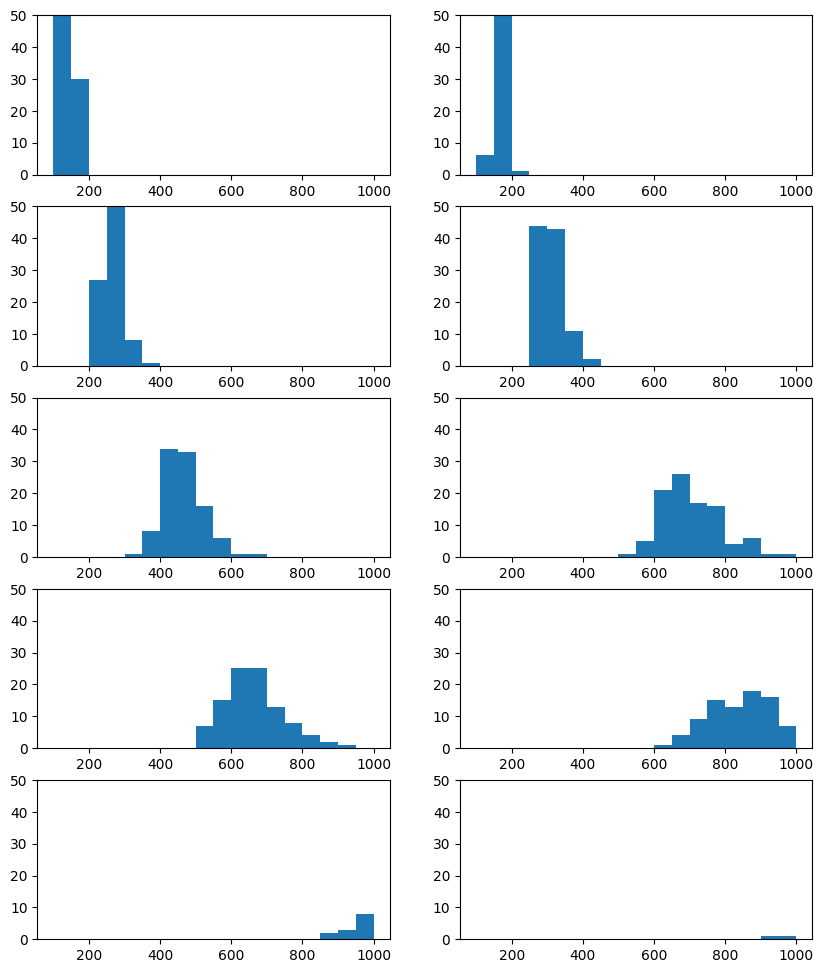

In [3]:
allfiles = ["data/superscale_sc100_275Rf_dnusc83Hz.npz", "data/superscale_sc100_250Rf_dnusc100Hz.npz", 
            "data/superscale_sc100_245Rf_dnusc157Hz.npz", "data/superscale_sc100_225Rf_dnusc186Hz.npz", 
            "data/superscale_sc100_205Rf_dnusc299Hz.npz", "data/superscale_sc100_205Rf_dnusc448Hz.npz",
            "data/superscale_sc100_165Rf_dnusc461Hz.npz", "data/superscale_sc100_140Rf_dnusc641Hz.npz", 
            "data/superscale_sc100_205Rf_dnusc747Hz.npz", "data/superscale_sc16_153Rf_dnusc805Hz.npz"]

fig, ax = plt.subplots(5, 2, figsize=(10, 12))
fig_idx = 0
bins = np.arange(100, 1001, 50)
finhist = np.zeros(len(bins)-1)
for file in allfiles:
    data = np.load(file)
    amp_nu = data["amp_nu"]
    dnu = data["dnu"]
    print(dnu)
    I_nu = np.abs(amp_nu)**2
    sband = np.zeros(I_nu.shape[0])
    for i in range(sband.shape[0]):
        sband[i] = scint_bandwidth(I_nu[i], dnu)
    bin_idx = np.digitize(sband, bins)
    finhist += np.histogram(sband, bins)[0]
    ax[fig_idx//2, fig_idx%2].hist(sband, bins)
    ax[fig_idx//2, fig_idx%2].set_ylim(0, 50)
    print(fig_idx)
    fig_idx += 1

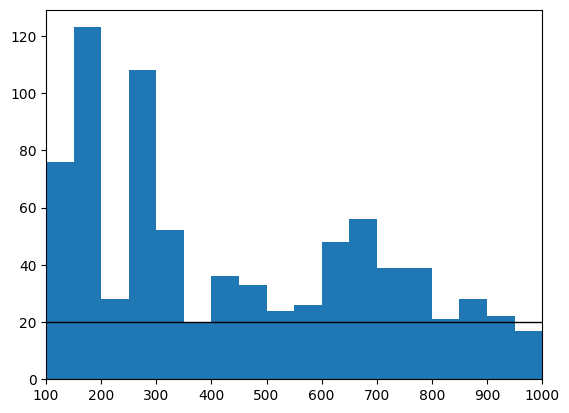

In [4]:
plt.stairs(finhist, bins, fill=True, edgecolor='black')
plt.xlim(100, 1000)
plt.axhline(20, color='black', linewidth=1)

In [7]:
bins = np.arange(100, 1001, 50)
flux_levels = np.logspace(np.log10(0.01), np.log10(10), 50)
bin_size_counter = np.zeros((flux_levels.shape[0], len(bins)-1), dtype=int)
tol = 1e-3
SEFD = 1.8
D = 20 #pc
NHI = 0.9045e21 # cm^-2
Ts = 50
max_burst_per_bin = 20
significance = np.ones((len(flux_levels), len(bins)-1, max_burst_per_bin)) * np.nan
for file in allfiles:
    data = np.load(file)
    amp_nu = data["amp_nu"]
    dnu = data["dnu"]
    steps = data["steps"]
    nu_center = data["nu0"]
    print(dnu)
    I_nu = np.abs(amp_nu)**2
    sband = np.zeros(I_nu.shape[0])
    for i in range(sband.shape[0]):
        sband[i] = scint_bandwidth(I_nu[i], dnu)
    nu = np.arange(nu_center - dnu*steps, nu_center + dnu*(steps+0.99), dnu)
    bin_idx = np.digitize(sband, bins)

    absline = AbsorptionLine(NHI, Ts, D, nu_center, 0)
    tau = absline.taunu(nu)
    I_norm = np.exp(-tau)
    I_norm_signal_idx = np.abs(1 - I_norm) > tol
    lower_idx = np.where(I_norm_signal_idx)[0][0]
    upper_idx = np.where(I_norm_signal_idx)[0][-1]
    int_processed = I_norm - np.mean(I_norm)
    for i, flux in enumerate(flux_levels):
        for j in range(1, len(bins)):
            burst_idx_arr = np.where(bin_idx == j)[0]
            for burst_idx in burst_idx_arr:
                if bin_size_counter[i,j-1] >= max_burst_per_bin:
                    break

                fluxnu = I_nu[burst_idx]/np.mean(I_nu[burst_idx]) * I_norm * flux + noise(nu.shape[0], SEFD, 0.001, dnu)
                observed_smoothed = signal.savgol_filter(fluxnu, int((upper_idx - lower_idx)/2), polyorder=1)
                
                obs_processed = observed_smoothed - np.mean(observed_smoothed)

                raw_cc = signal.correlate(obs_processed, int_processed, mode='full')

                # Compute standardized cross-correlation coefficients (-1 to +1)
                normalization = np.sqrt(np.sum(obs_processed**2) * np.sum(int_processed**2))
                cc_coefficients = raw_cc / normalization
                significance[i, j-1, bin_size_counter[i,j-1]] = np.max(cc_coefficients)
                bin_size_counter[i,j-1] += 1
    print(file)

50
data/superscale_sc100_275Rf_dnusc83Hz.npz
50
data/superscale_sc100_250Rf_dnusc100Hz.npz
50
data/superscale_sc100_245Rf_dnusc157Hz.npz
50
data/superscale_sc100_225Rf_dnusc186Hz.npz
100
data/superscale_sc100_205Rf_dnusc299Hz.npz
100
data/superscale_sc100_205Rf_dnusc448Hz.npz
100
data/superscale_sc100_165Rf_dnusc461Hz.npz
120
data/superscale_sc100_140Rf_dnusc641Hz.npz
120
data/superscale_sc100_205Rf_dnusc747Hz.npz
120
data/superscale_sc16_153Rf_dnusc805Hz.npz


[20 20 20 20 20 20 20 20 20 20 20 20 20 20 20 20 20 17]


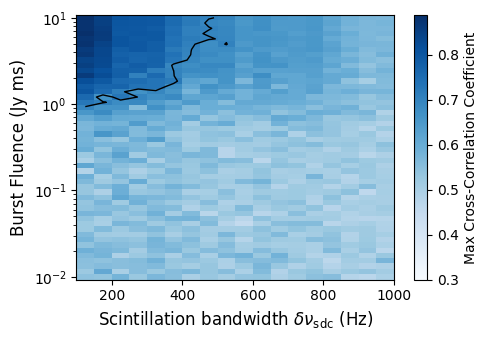

In [8]:
print(bin_size_counter[0])
fig, ax = plt.subplots(figsize=(5, 3.5))
X, Y = np.meshgrid(bins[:-1]+25, flux_levels)
mean_significance = np.nanmean(significance, axis=2)
pm = ax.pcolormesh(X, Y, mean_significance, shading='auto', cmap='Blues', vmin=0.3)
fig.colorbar(pm, ax=ax, label='Max Cross-Correlation Coefficient')
ax.contour(X, Y, mean_significance, levels=[0.7], colors='k', linewidths=1)
ax.set_xlabel(r'Scintillation bandwidth $\delta \nu_{\rm sdc}$ (Hz)', fontsize=12)
ax.set_ylabel('Burst Fluence (Jy ms)', fontsize=12)
ax.set_yscale('log')
plt.tight_layout()
# plt.savefig('plots/recale_singleburst_fluence_vs_sband_maxcorr.png', dpi=300)
plt.show()